# Churn - Logistic Regression

This notebook performs basic data exploration and trains a logistic regression model for customer churn. It refers to the original analysis in [churn_analysis.ipynb](<C:/D/Koenig/master/decision tree and random forest/churn_analysis.ipynb>) for additional context and prior preprocessing steps.


In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, classification_report

%matplotlib inline


In [2]:
# Load data (same file used in churn_analysis.ipynb)
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.shape


(7043, 21)

In [3]:
# Quick look
display(df.head())
print('Info:')
print(df.info())
print('Missing values by column:')
print(df.isnull().sum())
print('Target distribution:')
print(df['Churn'].value_counts())
print('Target distribution (pct):')
print(df['Churn'].value_counts(normalize=True))


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Info:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  

In [4]:
# Basic cleaning: convert TotalCharges to numeric (some entries may be spaces) and drop rows with missing TotalCharges
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
missing_tc = df['TotalCharges'].isnull().sum()
print('TotalCharges missing:', missing_tc)
if missing_tc > 0:
    df = df[df['TotalCharges'].notnull()].copy()

# Drop customerID (identifier)
if 'customerID' in df.columns:
    df = df.drop(columns=['customerID'])

# Map target to binary
df['Churn'] = df['Churn'].map({'Yes':1, 'No':0})

# Basic numeric cast for TotalCharges and MonthlyCharges and tenure
for c in ['tenure','MonthlyCharges','TotalCharges']:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')

df.shape


TotalCharges missing: 11


(7032, 20)

In [5]:
# One-hot encode categorical features (drop_first to avoid collinearity)
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
print('Categorical cols to encode:', cat_cols)
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True)
print('Encoded shape:', df_encoded.shape)

# Separate X and y
y = df_encoded['Churn']
X = df_encoded.drop(columns=['Churn'])

# Train-test split (stratify on target)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Train shape:', X_train.shape, 'Test shape:', X_test.shape)


Categorical cols to encode: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Encoded shape: (7032, 31)
Train shape: (5625, 30) Test shape: (1407, 30)


C:\Users\pauro\AppData\Local\Temp\ipykernel_35744\2519604277.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object']).columns.tolist()


In [6]:
# Train logistic regression
model = LogisticRegression(max_iter=1000, solver='lbfgs')
model.fit(X_train, y_train)

# Predictions and probabilities
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:,1]

# Evaluation metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)

print('Accuracy: {:.4f}'.format(acc))
print('Precision: {:.4f}'.format(prec))
print('Recall: {:.4f}'.format(rec))
print('F1-score: {:.4f}'.format(f1))
print('ROC AUC: {:.4f}'.format(roc_auc))

print('Classification report:')
print(classification_report(y_test, y_pred))

print('Confusion matrix:')
print(confusion_matrix(y_test, y_pred))


Accuracy: 0.8031
Precision: 0.6456
Recall: 0.5749
F1-score: 0.6082
ROC AUC: 0.8365
Classification report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407

Confusion matrix:
[[915 118]
 [159 215]]


c:\D\Koenig\master\.mldl\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


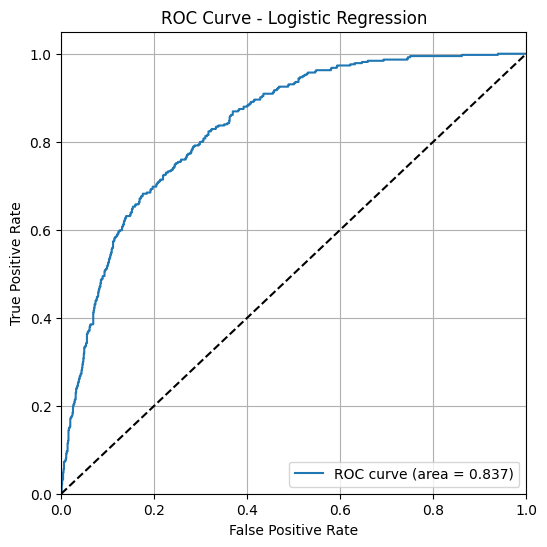

In [7]:
# ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label='ROC curve (area = %0.3f)' % roc_auc)
plt.plot([0,1],[0,1],'k--')
plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


## Notes and next steps
- This notebook performs a single baseline logistic regression.
- For production-ready models consider: feature scaling, cross-validation, hyperparameter tuning, handling class imbalance (e.g., class weights or resampling), and more careful feature engineering.
- For reproducibility, ensure the same preprocessing steps are applied when scoring new data (the original churn_analysis.ipynb has more EDA and alternative preprocessing that may be useful).


In [8]:
# --- Option A: dict-style input (user-friendly) ---
# Provide values using the original feature names (as in the raw dataset)
test_raw = {
    'gender': 'Female',
    'SeniorCitizen': 0,
    'Partner': 'Yes',
    'Dependents': 'No',
    'tenure': 12,
    'PhoneService': 'Yes',
    'MultipleLines': 'No',
    'InternetService': 'Fiber optic',
    'OnlineSecurity': 'No',
    'OnlineBackup': 'No',
    'DeviceProtection': 'No',
    'TechSupport': 'No',
    'StreamingTV': 'No',
    'StreamingMovies': 'No',
    'Contract': 'Month-to-month',
    'PaperlessBilling': 'Yes',
    'PaymentMethod': 'Electronic check',
    'MonthlyCharges': 70.70,
    'TotalCharges': 845.50
}

# Build DataFrame for the single row
test_df = pd.DataFrame([test_raw])

# Ensure numeric conversions for numeric columns
for num_col in ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']:
    if num_col in test_df.columns:
        test_df[num_col] = pd.to_numeric(test_df[num_col], errors='coerce')

# One-hot encode using the same categorical columns used for training
# (cat_cols should be the list of original categorical column names used in pd.get_dummies)
test_encoded = pd.get_dummies(test_df, columns=cat_cols, drop_first=True)

# Align columns to training features (X.columns) and fill missing columns with 0
test_encoded = test_encoded.reindex(columns=X.columns, fill_value=0)

# Predict
proba = model.predict_proba(test_encoded)[:, 1][0]
label = model.predict(test_encoded)[0]

print(f'Dict input -> Predicted probability of churn: {proba:.4f}')
print(f'Dict input -> Predicted label (1=Churn): {label}')

Dict input -> Predicted probability of churn: 0.3824
Dict input -> Predicted label (1=Churn): 0


### Feature Analysis

Top positive coefficients (increase predicted churn):
                              feature     coef  odds_ratio  mean_value
          InternetService_Fiber optic 0.683630    1.981055    0.440273
       PaymentMethod_Electronic check 0.390160    1.477217    0.336320
                 PaperlessBilling_Yes 0.298448    1.347765    0.592719
                    MultipleLines_Yes 0.278615    1.321298    0.421928
       MultipleLines_No phone service 0.252229    1.286891    0.096701
                      StreamingTV_Yes 0.205085    1.227629    0.384386
                        SeniorCitizen 0.196803    1.217505    0.162400
                  StreamingMovies_Yes 0.176875    1.193481    0.388367
           PaymentMethod_Mailed check 0.077059    1.080106    0.228100
PaymentMethod_Credit card (automatic) 0.038419    1.039166    0.216297

Top negative coefficients (decrease predicted churn):
                             feature      coef  odds_ratio  mean_value
                   Contract_Two year -1

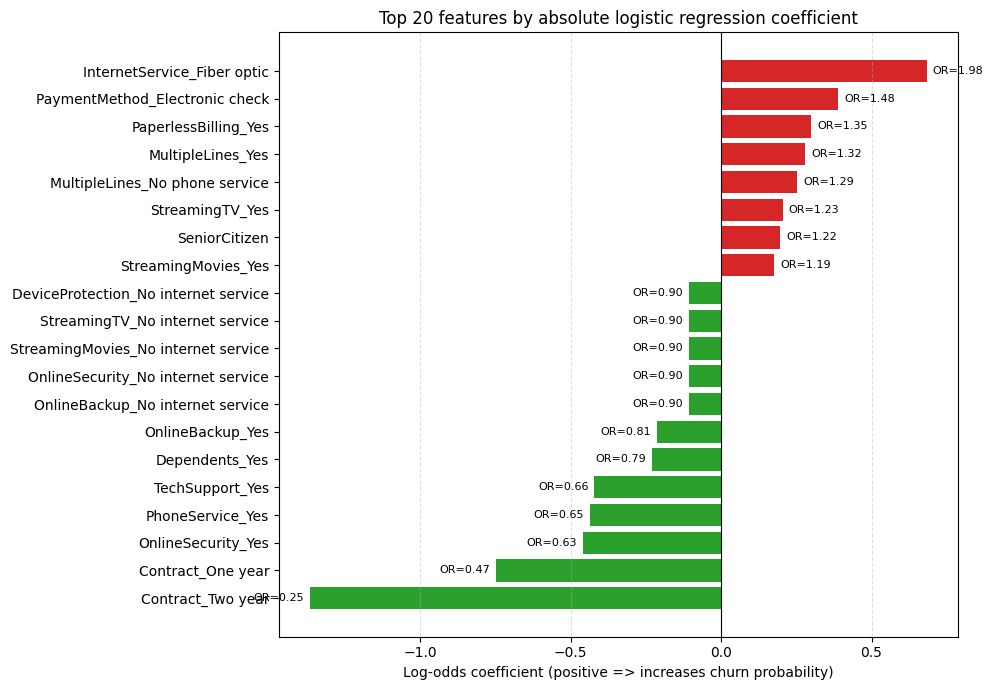

,feature,coef,abs_coef,odds_ratio,mean_value
0,Contract_Two year,-1.3667,1.366697,0.255,0.240
1,Contract_One year,-0.7487,0.748660,0.473,0.209
2,InternetService_Fiber optic,0.6836,0.683630,1.981,0.440
3,OnlineSecurity_Yes,-0.4600,0.459962,0.631,0.287
4,PhoneService_Yes,-0.4360,0.436050,0.647,0.903
5,TechSupport_Yes,-0.4207,0.420657,0.657,0.290
6,PaymentMethod_Electronic check,0.3902,0.390160,1.477,0.336
7,PaperlessBilling_Yes,0.2984,0.298448,1.348,0.593
8,MultipleLines_Yes,0.2786,0.278615,1.321,0.422
9,MultipleLines_No phone service,0.2522,0.252229,1.287,0.097


In [9]:
# Number of top features to display in the bar plot
top_n = 20

# Ensure model has coef_ (binary logistic regression)
if not hasattr(model, 'coef_'):
    raise AttributeError("The trained model does not expose 'coef_'. Ensure it's a sklearn LogisticRegression instance.")

# Extract coefficients (shape: (1, n_features) for binary)
coefs = model.coef_.ravel()
features = X.columns.to_list()

# Build DataFrame with coefficient info and simple feature-statistics for interpretation
feat_df = pd.DataFrame({
    'feature': features,
    'coef': coefs,
})
feat_df['abs_coef'] = feat_df['coef'].abs()
feat_df['odds_ratio'] = np.exp(feat_df['coef'])  # how odds change per unit increase
# use mean for numeric columns, and for binary/one-hot columns mean ~ prevalence
feat_df['mean_value'] = X.mean().values

# Sort by absolute importance
feat_df = feat_df.sort_values('abs_coef', ascending=False).reset_index(drop=True)

# Print top positive and top negative drivers
top_pos = feat_df[feat_df['coef'] > 0].head(10)
top_neg = feat_df[feat_df['coef'] < 0].head(10)

print("Top positive coefficients (increase predicted churn):")
print(top_pos[['feature','coef','odds_ratio','mean_value']].head(10).to_string(index=False))
print("\nTop negative coefficients (decrease predicted churn):")
print(top_neg[['feature','coef','odds_ratio','mean_value']].head(10).to_string(index=False))

# Bar plot of top_n features by absolute coefficient (signed bars)
plot_df = feat_df.head(top_n).sort_values('coef')  # sort by coef so negatives on left, positives on right
plt.figure(figsize=(10, max(6, top_n * 0.35)))
colors = ['#2ca02c' if v < 0 else '#d62728' for v in plot_df['coef']]  # green for negative (protective), red for positive (risk)
plt.barh(plot_df['feature'], plot_df['coef'], color=colors)
plt.axvline(0, color='k', linewidth=0.8)
plt.xlabel('Log-odds coefficient (positive => increases churn probability)')
plt.title(f'Top {top_n} features by absolute logistic regression coefficient')
plt.grid(axis='x', linestyle='--', alpha=0.4)

# Annotate bars with odds ratio (rounded)
for i, (coef, oratio) in enumerate(zip(plot_df['coef'], plot_df['odds_ratio'])):
    plt.text(coef + (0.02 if coef >= 0 else -0.02), i, f'OR={oratio:.2f}', va='center',
             ha=('left' if coef >= 0 else 'right'), color='black', fontsize=8)

plt.tight_layout()
plt.show()

# Optional: show full table of features sorted by importance
feat_df_display = feat_df.copy()
feat_df_display['coef'] = feat_df_display['coef'].round(4)
feat_df_display['odds_ratio'] = feat_df_display['odds_ratio'].round(3)
feat_df_display['mean_value'] = feat_df_display['mean_value'].round(3)
display(feat_df_display.head(50))  # show top 50 for quick inspection

### Saving the model

In [10]:
from joblib import dump, load
import os

# Save a single artifact containing model + metadata
out_path = r"C:\D\Koenig\master\logistic regression\customer_churn\churn_logistic_model.pkl"
artifact = {
    "model": model,
    "feature_names": X.columns.to_list(),
    "cat_cols": cat_cols
}
# Ensure directory exists (optional)
os.makedirs(os.path.dirname(out_path), exist_ok=True)

dump(artifact, out_path)
print(f"Saved model artifact to: {out_path}")



Saved model artifact to: C:\D\Koenig\master\logistic regression\customer_churn\churn_logistic_model.pkl


In [11]:
# Load saved model artifact and predict from a user-provided dict (test_raw)
from joblib import load
import pandas as pd
import numpy as np
import os

# Path to the saved artifact (use the same path you used to save)
pkl_path = out_path

# Load artifact
artifact = load(pkl_path)
model = artifact["model"]
feature_names = artifact["feature_names"]  # list of columns the model expects (X.columns)
cat_cols = artifact["cat_cols"]            # original categorical column names used for get_dummies

# Example user-provided dict (replace values with your test case)
test_raw = {
    'gender': 'Female',
    'SeniorCitizen': 0,
    'Partner': 'Yes',
    'Dependents': 'No',
    'tenure': 12,
    'PhoneService': 'Yes',
    'MultipleLines': 'No',
    'InternetService': 'Fiber optic',
    'OnlineSecurity': 'No',
    'OnlineBackup': 'No',
    'DeviceProtection': 'No',
    'TechSupport': 'No',
    'StreamingTV': 'No',
    'StreamingMovies': 'No',
    'Contract': 'Month-to-month',
    'PaperlessBilling': 'Yes',
    'PaymentMethod': 'Electronic check',
    'MonthlyCharges': 70.70,
    'TotalCharges': 845.50
}

# Build DataFrame for the single row
test_df = pd.DataFrame([test_raw])

# Coerce numeric columns that might be strings
for num_col in ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']:
    if num_col in test_df.columns:
        test_df[num_col] = pd.to_numeric(test_df[num_col], errors='coerce')

# One-hot encode categorical columns the same way used for training
test_encoded = pd.get_dummies(test_df, columns=cat_cols, drop_first=True)

# Align to the model's feature ordering; missing cols filled with 0
test_encoded = test_encoded.reindex(columns=feature_names, fill_value=0)

# Optional: check for any NaNs produced by coercion
if test_encoded.isnull().any().any():
    print("Warning: NaNs present in test row after processing. Check numeric fields.")
    print(test_encoded[test_encoded.isnull().any(axis=1)])

# Predict probability and class
proba = model.predict_proba(test_encoded)[:, 1][0]
label = model.predict(test_encoded)[0]

print(f"Predicted probability of churn: {proba:.4f}")
print(f"Predicted label (1=Churn): {label}")

Predicted probability of churn: 0.3824
Predicted label (1=Churn): 0


In [12]:
# Load saved model artifact and predict from a user-provided dict (test_raw)
from joblib import load
import pandas as pd
import numpy as np
import os

# Path to the saved artifact (use the same path you used to save)
pkl_path = out_path

# Load artifact
artifact = load(pkl_path)
model = artifact["model"]
feature_names = artifact["feature_names"]  # list of columns the model expects (X.columns)
cat_cols = artifact["cat_cols"]            # original categorical column names used for get_dummies

# Example user-provided dict (replace values with your test case)
test_raw = {
    'gender': 'Male',
    'SeniorCitizen': 1,
    'Partner': 'No',
    'Dependents': 'No',
    'tenure': 1,
    'PhoneService': 'Yes',
    'MultipleLines': 'No',
    'InternetService': 'Fiber optic',
    'OnlineSecurity': 'No',
    'OnlineBackup': 'No',
    'DeviceProtection': 'No',
    'TechSupport': 'No',
    'StreamingTV': 'Yes',
    'StreamingMovies': 'Yes',
    'Contract': 'Month-to-month',
    'PaperlessBilling': 'Yes',
    'PaymentMethod': 'Electronic check',
    'MonthlyCharges': 99.70,
    'TotalCharges': 99.50
}

# Build DataFrame for the single row
test_df = pd.DataFrame([test_raw])

# Coerce numeric columns that might be strings
for num_col in ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']:
    if num_col in test_df.columns:
        test_df[num_col] = pd.to_numeric(test_df[num_col], errors='coerce')

# One-hot encode categorical columns the same way used for training
test_encoded = pd.get_dummies(test_df, columns=cat_cols, drop_first=True)

# Align to the model's feature ordering; missing cols filled with 0
test_encoded = test_encoded.reindex(columns=feature_names, fill_value=0)

# Optional: check for any NaNs produced by coercion
if test_encoded.isnull().any().any():
    print("Warning: NaNs present in test row after processing. Check numeric fields.")
    print(test_encoded[test_encoded.isnull().any(axis=1)])

# Predict probability and class
proba = model.predict_proba(test_encoded)[:, 1][0]
label = model.predict(test_encoded)[0]

print(f"Predicted probability of churn: {proba:.4f}")
print(f"Predicted label (1=Churn): {label}")

Predicted probability of churn: 0.5450
Predicted label (1=Churn): 1
